<a href="https://colab.research.google.com/github/truong6478-svg/Videal-Internship-Phase3-Image-Classification/blob/main/3_2_ViT_CIFAR100.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Đang sử dụng thiết bị: cuda
Đang tải dữ liệu CIFAR-100...


100%|██████████| 169M/169M [22:20<00:00, 126kB/s] 


config.json:   0%|          | 0.00/502 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

[transformers] ViTForImageClassification LOAD REPORT from: google/vit-base-patch16-224-in21k
Key                 | Status     | 
--------------------+------------+-
pooler.dense.weight | UNEXPECTED | 
pooler.dense.bias   | UNEXPECTED | 
classifier.bias     | MISSING    | 
classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Bắt đầu fine-tune ViT trên CIFAR-100...
Epoch [1/3] - Train Loss: 1.1611, Train Acc: 79.66% | Test Loss: 0.5175, Test Acc: 85.99%
Epoch [2/3] - Train Loss: 0.3355, Train Acc: 90.49% | Test Loss: 0.5130, Test Acc: 85.67%
Epoch [3/3] - Train Loss: 0.2248, Train Acc: 93.34% | Test Loss: 0.5568, Test Acc: 85.16%


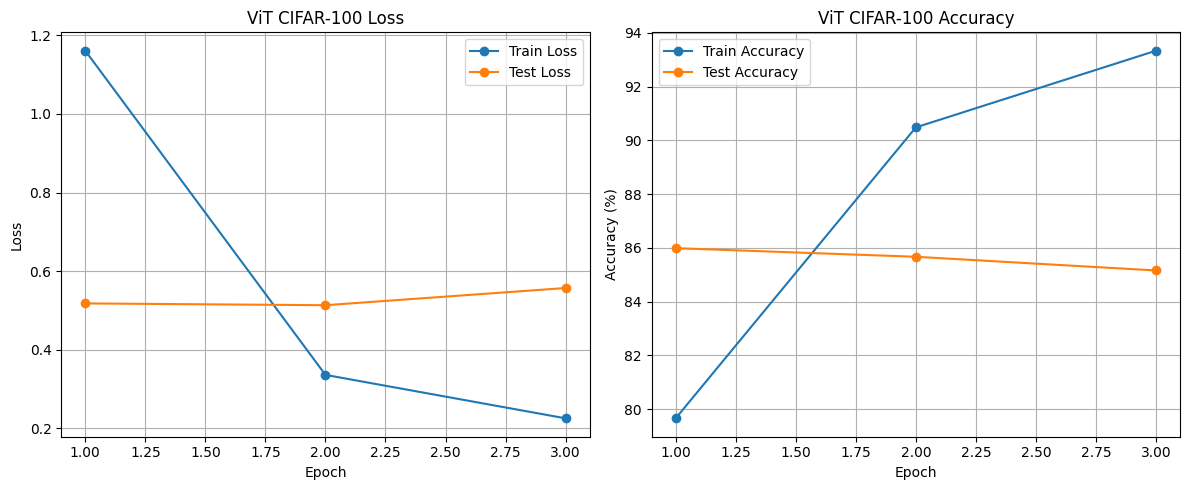

In [ ]:
!pip install -q transformers datasets accelerate torchvision matplotlib

!pip install -q transformers accelerate torchvision matplotlib

import os
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
import torchvision
import torchvision.transforms as transforms
from transformers import ViTForImageClassification, ViTImageProcessor
import matplotlib.pyplot as plt

# 1. Thiết lập thiết bị & thư mục lưu kết quả
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Đang sử dụng thiết bị:", device)
os.makedirs("results", exist_ok=True)
os.makedirs("data", exist_ok=True)

# 2. Tải processor, mô hình ViT pre-trained và dữ liệu CIFAR-100
model_name = "google/vit-base-patch16-224-in21k"
processor = ViTImageProcessor.from_pretrained(model_name)

transform_train = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(mean=processor.image_mean, std=processor.image_std),
])

transform_test = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=processor.image_mean, std=processor.image_std),
])

print("Đang tải dữ liệu CIFAR-100...")
trainset = torchvision.datasets.CIFAR100(
    root="./data", train=True, download=True, transform=transform_train
)
testset = torchvision.datasets.CIFAR100(
    root="./data", train=False, download=True, transform=transform_test
)

trainloader = DataLoader(trainset, batch_size=64, shuffle=True, num_workers=2, pin_memory=True)
testloader = DataLoader(testset, batch_size=64, shuffle=False, num_workers=2, pin_memory=True)

# 3. Khởi tạo mô hình ViT cho 100 lớp
model = ViTForImageClassification.from_pretrained(
    model_name,
    num_labels=100,
    ignore_mismatched_sizes=True
).to(device)

criterion = nn.CrossEntropyLoss()
optimizer = optim.AdamW(model.parameters(), lr=2e-4, weight_decay=0.01)
scaler = torch.amp.GradScaler("cuda", enabled=(device.type == "cuda"))

# 4. Huấn luyện và đánh giá
epochs = 3
train_losses, test_losses = [], []
train_accs, test_accs = [], []

print("Bắt đầu fine-tune ViT trên CIFAR-100...")
for epoch in range(epochs):
    model.train()
    running_loss, correct, total = 0.0, 0, 0
    for inputs, labels in trainloader:
        inputs, labels = inputs.to(device, non_blocking=True), labels.to(device, non_blocking=True)
        optimizer.zero_grad()

        with torch.amp.autocast("cuda", enabled=(device.type == "cuda")):
            outputs = model(pixel_values=inputs)
            logits = outputs.logits
            loss = criterion(logits, labels)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        running_loss += loss.item() * inputs.size(0)
        _, predicted = logits.max(1)
        total += labels.size(0)
        correct += predicted.eq(labels).sum().item()

    train_loss = running_loss / total
    train_acc = 100. * correct / total
    train_losses.append(train_loss)
    train_accs.append(train_acc)

    model.eval()
    t_loss, t_correct, t_total = 0.0, 0, 0
    with torch.no_grad():
        for inputs, labels in testloader:
            inputs, labels = inputs.to(device, non_blocking=True), labels.to(device, non_blocking=True)
            with torch.amp.autocast("cuda", enabled=(device.type == "cuda")):
                outputs = model(pixel_values=inputs)
                logits = outputs.logits
                loss = criterion(logits, labels)

            t_loss += loss.item() * inputs.size(0)
            _, predicted = logits.max(1)
            t_total += labels.size(0)
            t_correct += predicted.eq(labels).sum().item()

    test_loss = t_loss / t_total
    test_acc = 100. * t_correct / t_total
    test_losses.append(test_loss)
    test_accs.append(test_acc)

    print(
        f"Epoch [{epoch+1}/{epochs}] - "
        f"Train Loss: {train_loss:.4f}, Train Acc: {train_acc:.2f}% | "
        f"Test Loss: {test_loss:.4f}, Test Acc: {test_acc:.2f}%"
    )

# 5. Vẽ và lưu biểu đồ đánh giá
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(range(1, epochs + 1), train_losses, marker='o', label='Train Loss')
plt.plot(range(1, epochs + 1), test_losses, marker='o', label='Test Loss')
plt.title('ViT CIFAR-100 Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(range(1, epochs + 1), train_accs, marker='o', label='Train Accuracy')
plt.plot(range(1, epochs + 1), test_accs, marker='o', label='Test Accuracy')
plt.title('ViT CIFAR-100 Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy (%)')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.savefig("results/cifar100_eval_results.png", dpi=150)
plt.show()